# Clindent data preprocessing

Synchronize `Force.csv` and `LVDT.csv`, repair short native LVDT spikes, and export synchronized force and displacement for each indentation cycle. Run all cells with the **Dataprocess** environment. The default input is `data/Clindent_Data/400g/`, including `Trial0` through `Trial3`.

Set `ENABLE_STEADY_STATE_SEGMENTATION = True` to export only the detected steady-force interval. Set it to `False` (default) to export the full loading and hold interval, from the **moving to bottom** command until the **moving to top** command starts unloading. Set `EXPORT_DURATION_S = 60.0` to retain exactly 60 seconds from the first selected sample in either mode; leave it as `None` to retain the whole selected interval. If no sequence log exists, force-based detection estimates the cycle boundaries using the configured pre-trigger and release guard.

Each output CSV has exactly these columns: **`Time, s`**, **`Indentation Position, mm`**, **`Indentation Force, N`**. Both signals use **linear interpolation at 200 Hz** (0.005 s spacing) on a common grid. Time starts at zero at the first retained sample. Three cycles from `Trial0` become `Trial0_1.csv`, `Trial0_2.csv`, and `Trial0_3.csv` in `data/Clindent_Data/400g/synchronized/Indentation_01/`, `Indentation_02/`, and `Indentation_03/`, respectively. The same cycle number from every trial shares one folder.

Review the plots before running the final export cell. This notebook does not fit a model.

In [13]:
from pathlib import Path
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display


def find_project_root(start):
    for candidate in (start, *start.parents):
        if (candidate / 'data_process' / 'utils' / 'creep_force_preprocessing.py').is_file():
            return candidate
    raise FileNotFoundError('Start the notebook from within the Tonometry_Control_Code project.')


PROJECT_ROOT = find_project_root(Path.cwd().resolve())
sys.path.insert(0, str(PROJECT_ROOT / 'data_process' / 'utils'))
from creep_force_preprocessing import (
    OUTPUT_COLUMNS, load_trial, detect_indentation_cycles, segment_force_steady_state,
    extract_indentation_cycles,
)

INPUT_DIR = PROJECT_ROOT / 'data' / 'Clindent_Data' / '400g'
OUTPUT_DIR = INPUT_DIR / 'synchronized'
TRIAL_NAMES = ['Trial0','Trial1','Trial2','Trial3']  # Use None to discover all raw trial directories.
SAMPLING_HZ = 200.0
DT_S = 1.0 / SAMPLING_HZ
BASELINE_S = 0.8
MAX_INTERPOLATION_GAP_S = 0.2
FORCE_AXIS = 'Fz'
COMPRESSION_SIGN = -1.0
DISPLACEMENT_SIGN = 1.0
DISPLACEMENT_DESPIKE_SETTINGS = dict(
    window_s=0.2, threshold=0.12, n_sigma=6.0, max_duration_s=0.06, max_gap_s=0.2,
)
CYCLE_METHOD = 'auto'  # Prefer sequence logs; alternatives: 'sequence' or 'force'.
FORCE_SEGMENTATION_SETTINGS = dict(
    min_force_n=0.2, on_fraction=0.2, off_fraction=0.1, onset_fraction=0.05,
    debounce_s=0.1, min_loaded_s=5.0, smoothing_s=0.1,
)
FORCE_RELEASE_GUARD_S = 0.3  # Conservative trimming for force-only boundary estimates.
FORCE_PRE_INDENT_S = 0.2  # Preserve the initial ramp in the force-only fallback.
ENABLE_STEADY_STATE_SEGMENTATION = False  # False keeps the full loading and hold interval.
EXPORT_DURATION_S = 50.0  # Set to 60.0 for a 60-second export in either mode.
FORCE_STEADY_STATE_SETTINGS = dict(
    stability_window_s=0.5, stable_confirm_s=0.5, plateau_tail_s=5.0,
    level_tolerance_fraction=0.05, stable_std_fraction=0.03,
    stable_slope_fraction=0.05, release_guard_s=0.25, min_force_n=0.2,
)
# Used only with steady-state segmentation: positive delays, negative advances.
STEADY_START_OFFSET_S = 15.0
STEADY_END_OFFSET_S = 0.0
SAVE_FIGURES = False
plt.rcParams.update({'axes.grid': True, 'grid.alpha': 0.25})


def save_figure(fig, filename):
    if SAVE_FIGURES:
        figure_dir = OUTPUT_DIR / 'figures'
        figure_dir.mkdir(parents=True, exist_ok=True)
        fig.savefig(figure_dir / filename, dpi=160, bbox_inches='tight')


print(f'Input: {INPUT_DIR}')
print(f'Output: {OUTPUT_DIR}')
print(f'Sampling: {SAMPLING_HZ:g} Hz; linear interpolation; dt = {DT_S:g} s')
print(f'Steady-state segmentation: {ENABLE_STEADY_STATE_SEGMENTATION}')
print(f'Export duration: {EXPORT_DURATION_S} s')

Input: /Users/kaiwenzuo/Library/CloudStorage/OneDrive-CaseWesternReserveUniversity/CWRU/Kaiwen_git_repos/Tonometry_Control_Code/data/Clindent_Data/400g
Output: /Users/kaiwenzuo/Library/CloudStorage/OneDrive-CaseWesternReserveUniversity/CWRU/Kaiwen_git_repos/Tonometry_Control_Code/data/Clindent_Data/400g/synchronized
Sampling: 200 Hz; linear interpolation; dt = 0.005 s
Steady-state segmentation: False
Export duration: 50.0 s


## Clean native samples and synchronize

Use the recorded integer nanosecond timestamps with one shared origin, rather than aligning separate `elapsed_time` columns. Mask invalid LVDT voltages outside `(0.1, 9.99)` V. Repair only short returning excursions on the native LVDT timeline using linear interpolation; retain genuine steps. Do not smooth or despike force.

Subtract the median of the first 0.8 s from each native signal, then apply the configured signs so compression and indentation are positive. Preserve this **single trial-wide baseline** in every exported cycle, including residual indentation in later cycles. Do not zero displacement independently for each export.

Interpolate both cleaned signals directly from native samples onto the shared 200 Hz grid over their overlapping acquisition interval. There is no bin averaging or median resampling. Do not extrapolate or bridge sensor gaps longer than 0.2 s; reject any retained interval containing an unresolved gap rather than deleting grid rows.

In [14]:
if TRIAL_NAMES is None:
    trial_dirs = sorted(
        path for path in INPUT_DIR.iterdir()
        if path.is_dir() and (path / 'Force.csv').is_file() and (path / 'LVDT.csv').is_file()
    )
else:
    if len(TRIAL_NAMES) != len(set(TRIAL_NAMES)):
        raise ValueError('TRIAL_NAMES must not contain duplicates.')
    trial_dirs = [INPUT_DIR / name for name in TRIAL_NAMES]
if not trial_dirs:
    raise FileNotFoundError(f'No raw Clindent trials were found in {INPUT_DIR}.')

processed = []
quality_rows = []
for trial_dir in trial_dirs:
    trial = load_trial(
        trial_dir, dt=DT_S, baseline_s=BASELINE_S, max_gap_s=MAX_INTERPOLATION_GAP_S,
        force_axis=FORCE_AXIS, compression_sign=COMPRESSION_SIGN,
        displacement_sign=DISPLACEMENT_SIGN,
        displacement_despike=DISPLACEMENT_DESPIKE_SETTINGS, force_despike=None,
    )
    cycles = detect_indentation_cycles(
        trial_dir, trial, method=CYCLE_METHOD, force_settings=FORCE_SEGMENTATION_SETTINGS,
        force_release_guard_s=FORCE_RELEASE_GUARD_S, force_pre_indent_s=FORCE_PRE_INDENT_S,
    )
    if cycles.onset_s.min() < BASELINE_S:
        raise ValueError(f'{trial_dir.name}: Shorten BASELINE_S so it ends before indentation.')
    processed.append(dict(name=trial_dir.name, source=trial_dir, trial=trial, cycles=cycles))
    quality_rows.append({
        'trial': trial_dir.name, 'force_samples': len(trial['force']),
        'lvdt_samples': len(trial['lvdt']),
        'invalid_lvdt_samples': int((~trial['lvdt'].sensor_valid).sum()),
        'repaired_lvdt_spikes': int(trial['lvdt'].displacement_spike.sum()),
        'unresolved_grid_samples': int((~trial['sync'].valid).sum()),
        'detected_cycles': len(cycles),
    })

quality_summary = pd.DataFrame(quality_rows)
display(quality_summary)

,trial,force_samples,lvdt_samples,invalid_lvdt_samples,repaired_lvdt_spikes,unresolved_grid_samples,detected_cycles
0,Trial0,221915,55882,4,215,0,3
1,Trial1,147072,45681,9,136,0,3
2,Trial2,363052,201619,28,965,0,3
3,Trial3,53403,28835,0,24,0,1


## Select the export interval

With `ENABLE_STEADY_STATE_SEGMENTATION = False`, retain the entire detected cycle (`onset_s <= time_s < release_s`). Skip steady-force detection, its release guard, and both `STEADY_*_OFFSET_S` adjustments. Loading and settling remain in the export; unloading and recovery are excluded. Missing sensor values anywhere in the retained interval still raise an error. Force-only cycle detection retains its configured pre-trigger and release guard.

With `ENABLE_STEADY_STATE_SEGMENTATION = True`, use the following steady-force selection. In either mode, set `EXPORT_DURATION_S` to a multiple of 0.005 s (for example, `60.0`) to retain that many seconds from the first selected sample. A 60 s export contains 12,000 samples, with its last time value at 59.995 s. `None` keeps the whole selected interval. If the interval is too short, selection raises an error before export. For 60 s steady-force exports from the current trials, also set `STEADY_START_OFFSET_S = 0.0`; the configured 15 s delay leaves some steady intervals too short.

Within each detected indentation cycle, estimate the holding force from the median of the last `plateau_tail_s` seconds before the guarded release boundary. A full trailing `stability_window_s` window must have a mean within `level_tolerance_fraction` of that level, a standard deviation no greater than `stable_std_fraction` of the level, and an absolute linear-regression slope no greater than `stable_slope_fraction` times the level per second. The defaults are **0.5 s**, **5%**, **3%**, and **5%/s**, respectively. These statistics only detect boundaries; the exported force remains unsmoothed.

Require those conditions continuously for `stable_confirm_s` (default **0.5 s**). Start the export at the first qualifying window endpoint in that confirmed run. Keep one continuous interval until `release_guard_s` (default **0.25 s**) before release, or end earlier at the start of a later sustained loss of force stability. Shorter fluctuations remain in the continuous record. Never concatenate separated intervals or delete individual rows to hide sensor gaps. A cycle without a confirmed steady-force interval raises an error.

After automatic detection, `STEADY_START_OFFSET_S` and `STEADY_END_OFFSET_S` shift the left and right boundaries for every trial and cycle. Positive values delay a boundary; negative values advance it. For example, start `-0.5` and end `1.0` include 0.5 s earlier and 1.0 s later than the detected interval. A manual extension can include non-steady force. The adjusted interval must remain within the indentation command and release boundaries, contain at least two samples, and contain no missing sensor values; invalid adjustments raise an error rather than being clipped. Selection uses the existing 200 Hz grid: the first retained timestamp is at or after the adjusted start, and the end is exclusive. Rerun the selection and plotting cells after changing the option or offsets, then review the plots before exporting. The manifest records detected boundaries, offsets, and adjusted boundaries.

Export the displacement and measured force at exactly the same retained timestamps. Reset **time only** to zero at the first retained sample; preserve the trial-wide displacement and force baselines. Original command times, export boundaries, and the selected mode are recorded in `_cycle_manifest.csv`. Steady-force boundaries, holding force, offsets, and detection settings are recorded only when steady-state segmentation is enabled.

In [15]:
if EXPORT_DURATION_S is not None and (
        not np.isfinite(EXPORT_DURATION_S) or EXPORT_DURATION_S < 2 * DT_S
        or not np.isclose(EXPORT_DURATION_S * SAMPLING_HZ,
                          round(EXPORT_DURATION_S * SAMPLING_HZ), rtol=0, atol=1e-8)):
    raise ValueError('EXPORT_DURATION_S must be at least two samples and a multiple of the sampling interval.')
if ENABLE_STEADY_STATE_SEGMENTATION and not np.isfinite(
        [STEADY_START_OFFSET_S, STEADY_END_OFFSET_S]).all():
    raise ValueError('Steady-state boundary offsets must be finite seconds.')

segment_label = 'steady-force' if ENABLE_STEADY_STATE_SEGMENTATION else 'full-load'
cycle_rows = []
for result in processed:
    trial, trial_dir = result['trial'], result['source']
    # Discard prior selections so changing modes cannot reuse stale steady boundaries.
    cycles = result['cycles'][['cycle', 'onset_s', 'release_s', 'boundary_source']].copy()
    if ENABLE_STEADY_STATE_SEGMENTATION:
        cycles = segment_force_steady_state(
            trial['sync'], cycles, **FORCE_STEADY_STATE_SETTINGS,
        )
        cycles['detected_steady_start_s'] = cycles.steady_start_s
        cycles['detected_steady_end_s'] = cycles.steady_end_s
        cycles['steady_start_s'] += STEADY_START_OFFSET_S
        cycles['steady_end_s'] += STEADY_END_OFFSET_S
    cycles['export_start_s'] = cycles.steady_start_s if ENABLE_STEADY_STATE_SEGMENTATION else cycles.onset_s
    cycles['export_end_s'] = cycles.steady_end_s if ENABLE_STEADY_STATE_SEGMENTATION else cycles.release_s
    if EXPORT_DURATION_S is not None:
        times = trial['sync'].time_s.to_numpy()
        samples = round(EXPORT_DURATION_S * SAMPLING_HZ)
        for index, event in cycles.iterrows():
            first = np.searchsorted(times, event.export_start_s)
            available = np.searchsorted(times, event.export_end_s) - first
            if available < samples:
                raise ValueError(f'{trial_dir.name} cycle {event.cycle}: '
                                 f'Only {available / SAMPLING_HZ:g} s available; '
                                 f'EXPORT_DURATION_S requests {EXPORT_DURATION_S:g} s.')
            next_sample = first + samples
            cycles.at[index, 'export_end_s'] = (min(times[next_sample], event.export_end_s)
                                                if next_sample < len(times) else event.export_end_s)
        if ENABLE_STEADY_STATE_SEGMENTATION:
            cycles['steady_end_s'] = cycles.export_end_s
    export_cycles = cycles.copy()
    if not ENABLE_STEADY_STATE_SEGMENTATION:
        export_cycles['release_s'] = cycles.export_end_s
    extracted = extract_indentation_cycles(
        trial['sync'], export_cycles, sampling_hz=SAMPLING_HZ,
        steady_only=ENABLE_STEADY_STATE_SEGMENTATION,
    )
    result.update(cycles=cycles, extracted=extracted)
    for event, (cycle_number, frame) in zip(cycles.itertuples(), extracted):
        retained = trial['sync'].loc[
            (trial['sync'].time_s >= event.export_start_s)
            & (trial['sync'].time_s < event.export_end_s)
        ]
        cycle_rows.append({
            'file': f'Indentation_{cycle_number:02d}/{result["name"]}_{cycle_number}.csv',
            'source_trial': str(trial_dir.relative_to(PROJECT_ROOT)),
            'origin_ns': trial['origin_ns'], 'cycle': cycle_number,
            'boundary_source': event.boundary_source,
            'steady_state_segmentation': ENABLE_STEADY_STATE_SEGMENTATION,
            'export_scope': 'steady_force_only' if ENABLE_STEADY_STATE_SEGMENTATION else 'full_load',
            'indent_command_s': event.onset_s, 'release_boundary_s': event.release_s,
            'export_start_host_s': event.export_start_s,
            'export_end_host_s': event.export_end_s,
            'export_start_cycle_s': event.export_start_s - event.onset_s,
            'first_retained_host_s': retained.time_s.iloc[0],
            'last_retained_host_s': retained.time_s.iloc[-1],
            'rows': len(frame), 'duration_s': frame[OUTPUT_COLUMNS[0]].iloc[-1],
            'sampling_hz': SAMPLING_HZ,
            'force_native_baseline_n': trial['baseline']['force_raw_n'],
            'position_native_baseline_mm': trial['baseline']['displacement_raw_mm'],
            **({
                'detected_steady_start_host_s': event.detected_steady_start_s,
                'detected_steady_end_host_s': event.detected_steady_end_s,
                'steady_start_offset_s': STEADY_START_OFFSET_S,
                'steady_end_offset_s': STEADY_END_OFFSET_S,
                'steady_start_host_s': event.steady_start_s,
                'steady_end_host_s': event.steady_end_s,
                'steady_start_cycle_s': event.steady_start_s - event.onset_s,
                'steady_force_n': event.steady_force_n,
                **{f'steady_{key}': value for key, value in FORCE_STEADY_STATE_SETTINGS.items()},
            } if ENABLE_STEADY_STATE_SEGMENTATION else {}),
        })

cycle_summary = pd.DataFrame(cycle_rows)
display(cycle_summary[['file', 'export_scope', 'export_start_cycle_s',
                       'rows', 'duration_s', 'sampling_hz']])

,file,export_scope,export_start_cycle_s,rows,duration_s,sampling_hz
0,Indentation_01/Trial0_1.csv,full_load,0.0,10000,49.995,200.0
1,Indentation_02/Trial0_2.csv,full_load,0.0,10000,49.995,200.0
2,Indentation_03/Trial0_3.csv,full_load,0.0,10000,49.995,200.0
3,Indentation_01/Trial1_1.csv,full_load,0.0,10000,49.995,200.0
4,Indentation_02/Trial1_2.csv,full_load,0.0,10000,49.995,200.0
5,Indentation_03/Trial1_3.csv,full_load,0.0,10000,49.995,200.0
6,Indentation_01/Trial2_1.csv,full_load,0.0,10000,49.995,200.0
7,Indentation_02/Trial2_2.csv,full_load,0.0,10000,49.995,200.0
8,Indentation_03/Trial2_3.csv,full_load,0.0,10000,49.995,200.0
9,Indentation_01/Trial3_1.csv,full_load,0.0,10000,49.995,200.0


## Check synchronization, spike removal, and export boundaries

Colored shading shows the intervals retained for export. Dotted lines mark export starts and dashed lines mark release commands. With steady-state segmentation enabled, light gray shading shows the excluded loading and settling interval. With it disabled, the retained interval spans the full detected cycle. Gray LVDT traces show valid native data before spike repair; the cleaned signal is interpolated at 200 Hz. Review the thresholds if real loading steps are marked as spikes. For force-only cycle detection, release boundaries are estimates and the cycle-detection release guard still applies.

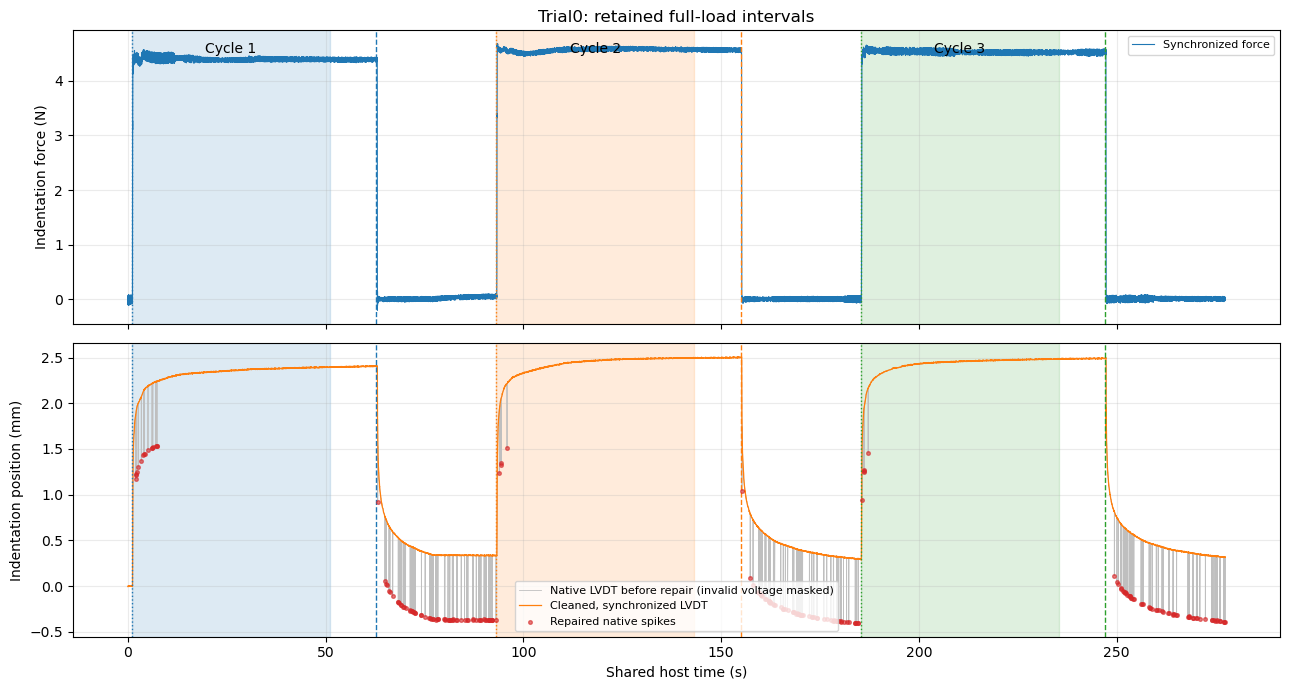

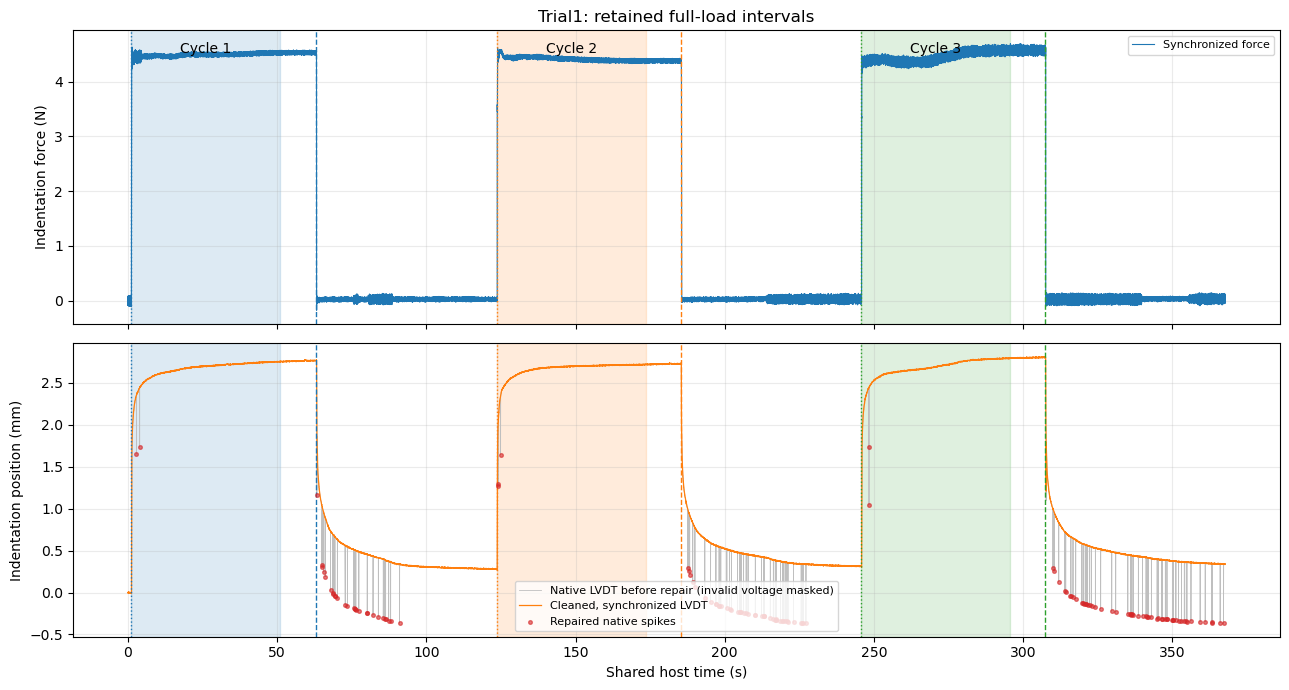

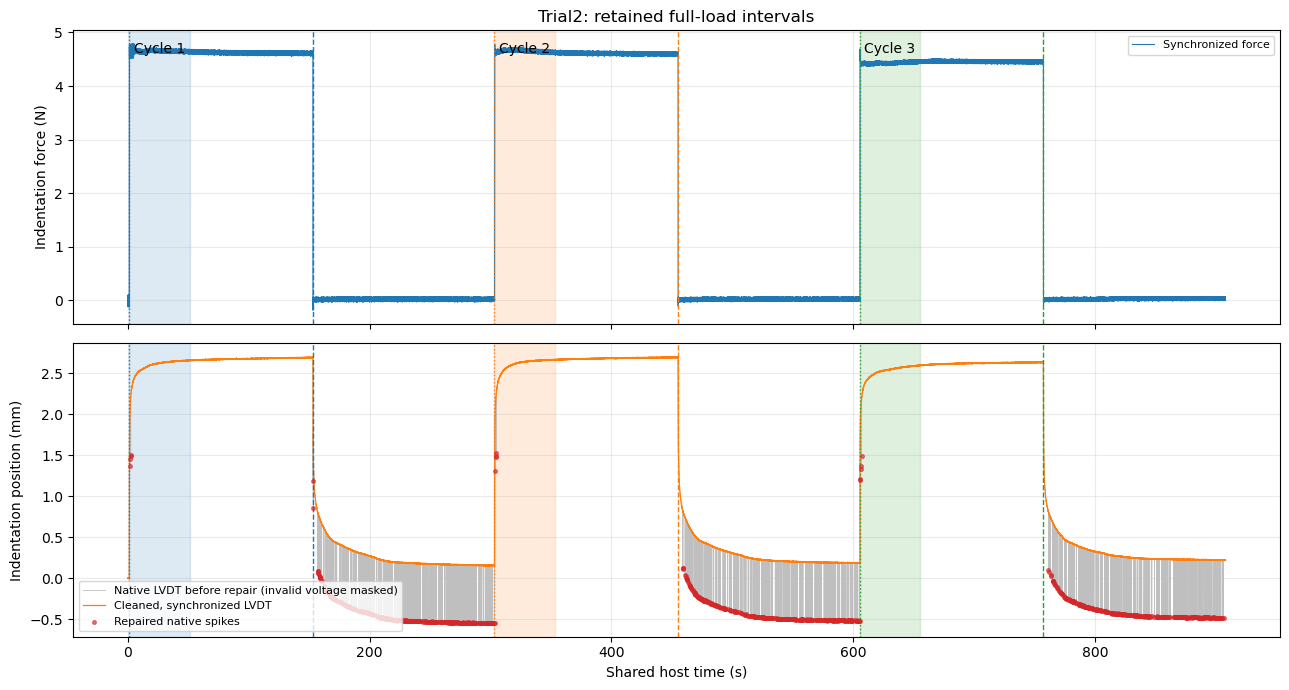

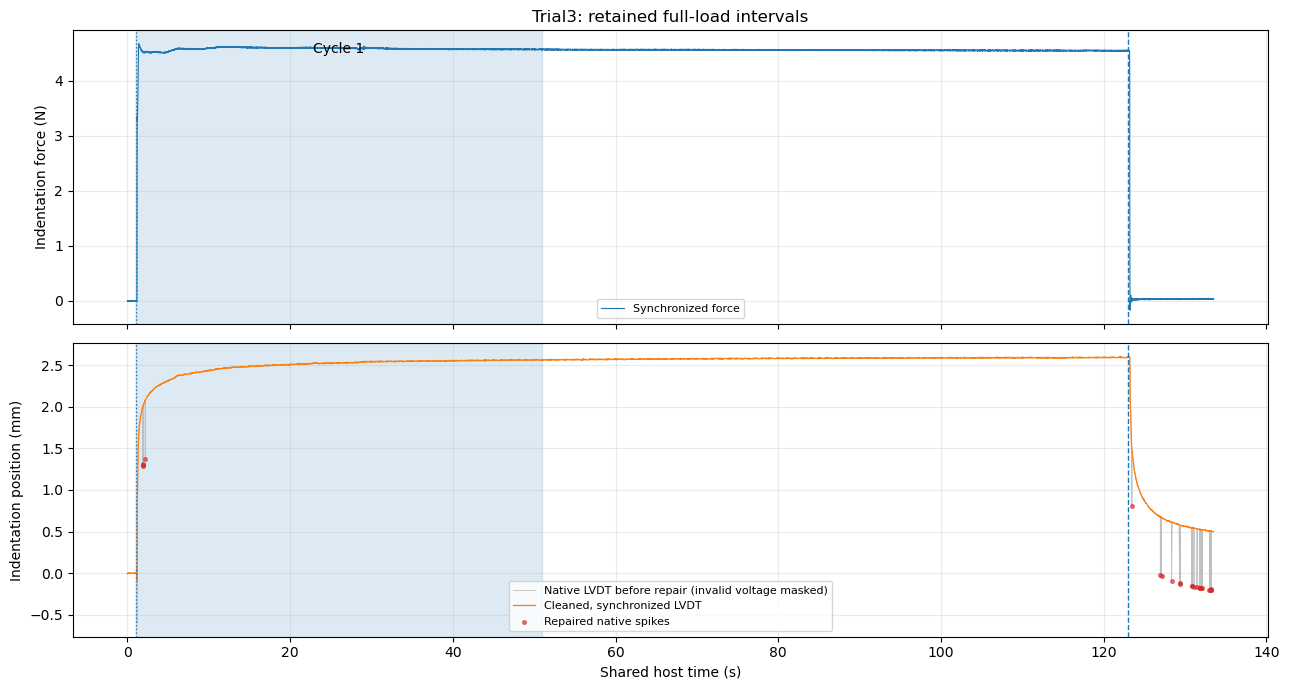

In [16]:
for result in processed:
    trial, cycles = result['trial'], result['cycles']
    sync, lvdt = trial['sync'], trial['lvdt']
    fig, axes = plt.subplots(2, 1, figsize=(13, 7), sharex=True)
    axes[0].plot(sync.time_s, sync.force_n, color='tab:blue', lw=0.8, label='Synchronized force')
    axes[1].plot(lvdt.time_s, lvdt.displacement_before_despike_mm,
                 color='0.75', lw=0.6, label='Native LVDT before repair (invalid voltage masked)')
    axes[1].plot(sync.time_s, sync.displacement_mm, color='tab:orange', lw=0.9,
                 label='Cleaned, synchronized LVDT')
    spike = lvdt.displacement_spike
    axes[1].scatter(lvdt.loc[spike, 'time_s'], lvdt.loc[spike, 'displacement_before_despike_mm'],
                    color='tab:red', s=7, alpha=0.6, label='Repaired native spikes', zorder=3)
    for event in cycles.itertuples():
        color = plt.get_cmap('tab10')((event.cycle - 1) % 10)
        for axis in axes:
            axis.axvspan(event.onset_s, event.export_start_s, color='0.5', alpha=0.12)
            axis.axvspan(event.export_start_s, event.export_end_s, color=color, alpha=0.15)
            axis.axvline(event.export_start_s, color=color, ls=':', lw=1)
            axis.axvline(event.release_s, color=color, ls='--', lw=1)
        axes[0].text((event.export_start_s + event.export_end_s) / 2, 0.96,
                     f'Cycle {event.cycle}', transform=axes[0].get_xaxis_transform(),
                     ha='center', va='top')
    axes[0].set(title=f"{result['name']}: retained {segment_label} intervals",
                 ylabel='Indentation force (N)')
    axes[1].set(xlabel='Shared host time (s)', ylabel='Indentation position (mm)')
    for axis in axes:
        axis.legend(loc='best', fontsize=8)
    fig.tight_layout()
    save_figure(fig, f"{result['name']}_synchronization.png")
    plt.show()
    plt.close(fig)

## Visualize every exported segment

Columns show raw trials, with force and displacement sharing the same time axis relative to the first retained sample. Loading and settling are included when `ENABLE_STEADY_STATE_SEGMENTATION = False`; steady-state mode trims them according to its detection settings and offsets. The overlay compares all retained segments within each raw trial.

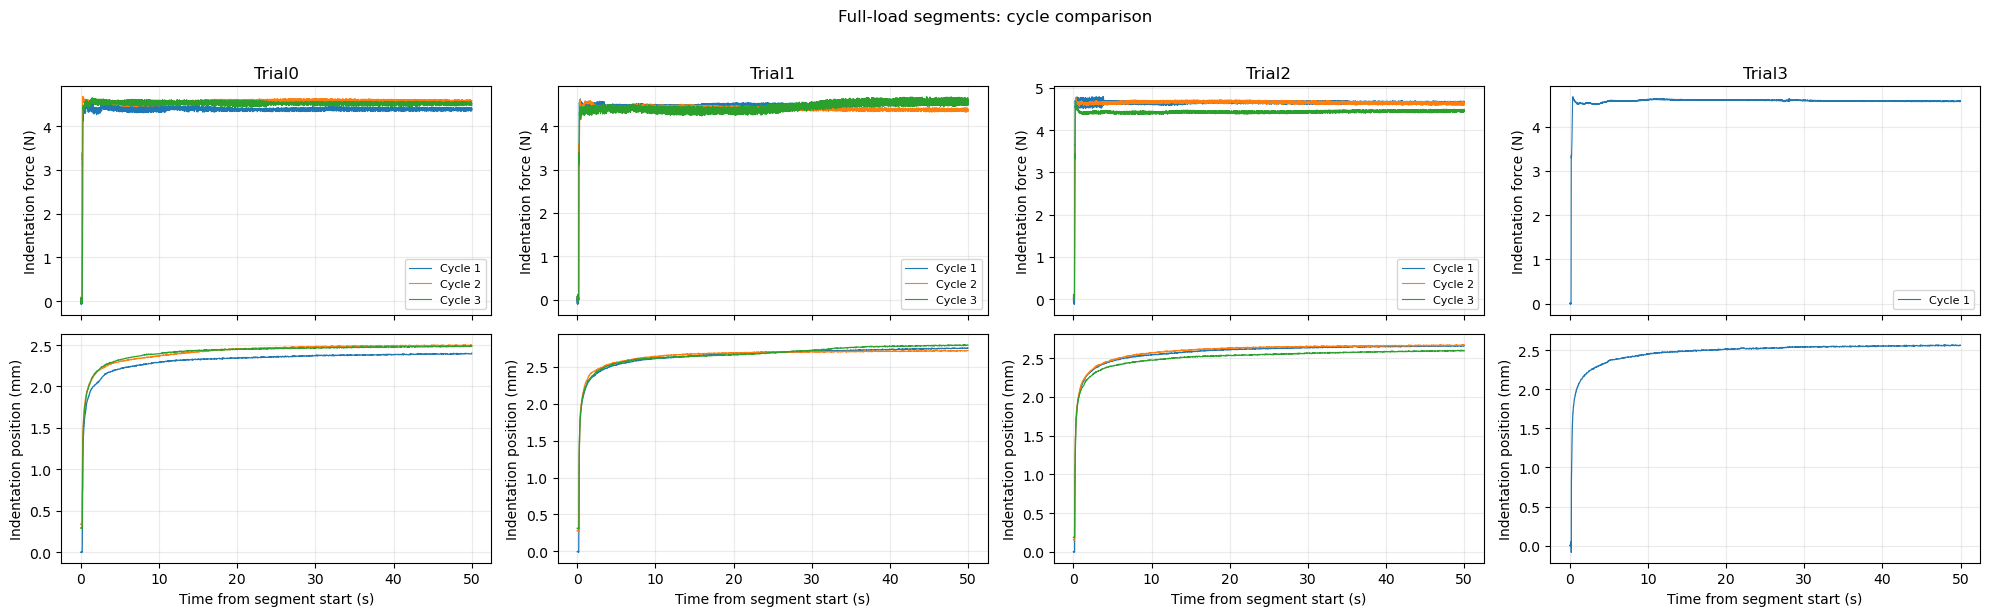

In [17]:
fig, axes = plt.subplots(2, len(processed), figsize=(5 * len(processed), 6),
                         sharex='col', squeeze=False)
for column, result in enumerate(processed):
    for cycle_number, frame in result['extracted']:
        time = frame[OUTPUT_COLUMNS[0]]
        line, = axes[0, column].plot(time, frame[OUTPUT_COLUMNS[2]], lw=0.8, label=f'Cycle {cycle_number}')
        axes[1, column].plot(time, frame[OUTPUT_COLUMNS[1]], lw=0.9, color=line.get_color())
    axes[0, column].set(title=result['name'], ylabel='Indentation force (N)')
    axes[1, column].set(xlabel='Time from segment start (s)', ylabel='Indentation position (mm)')
    axes[0, column].legend(fontsize=8)
fig.suptitle(f'{segment_label.capitalize()} segments: cycle comparison', y=1.02)
fig.tight_layout()
save_figure(fig, 'all_cycle_overlays.png')
plt.show()
plt.close(fig)

## Export synchronized cycle CSVs

All selected trials and export intervals have been validated before writing. Each cycle is saved in `Indentation_01/`, `Indentation_02/`, etc., under `OUTPUT_DIR`, retaining filenames such as `Trial0_1.csv`. Running this cell overwrites cycle CSVs for the selected raw trials and removes their obsolete numbered exports from the output root and indentation folders. Both segmentation modes use the same output paths. Raw measurements remain untouched. `_cycle_manifest.csv` stays in `OUTPUT_DIR` and stores output-relative file paths, segmentation mode, export boundaries, original timing, baseline, and cycle metadata separately so that every cycle CSV retains exactly the required three columns. Steady-force diagnostics are included only when that mode is enabled.

`data_process/Load_Profile-Creep_Curve_Fit_Kelvin.ipynb` fits a constant-force hold response. Full-load exports include the loading ramp and may include zero or negative baseline-corrected force; select a steady hold or use a force-history model before fitting those exports.

In [18]:
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
exported_paths = []
for result in processed:
    expected_paths = {
        OUTPUT_DIR / f"Indentation_{cycle_number:02d}" / f"{result['name']}_{cycle_number}.csv"
        for cycle_number, _ in result['extracted']
    }
    for cycle_number, frame in result['extracted']:
        cycle_dir = OUTPUT_DIR / f"Indentation_{cycle_number:02d}"
        cycle_dir.mkdir(parents=True, exist_ok=True)
        output_path = cycle_dir / f"{result['name']}_{cycle_number}.csv"
        frame.to_csv(output_path, index=False, float_format='%.10f')
        exported_paths.append(output_path)
        print(f'{output_path.relative_to(OUTPUT_DIR)}: {len(frame):,} rows at {SAMPLING_HZ:g} Hz')
    old_paths = list(OUTPUT_DIR.glob(f"{result['name']}_*.csv"))
    old_paths.extend(OUTPUT_DIR.glob(f"Indentation_[0-9][0-9]*/{result['name']}_*.csv"))
    for old_path in old_paths:
        suffix = old_path.stem[len(result['name']) + 1:]
        if suffix.isdigit() and old_path not in expected_paths:
            old_path.unlink()

manifest_path = OUTPUT_DIR / '_cycle_manifest.csv'
if manifest_path.exists():
    previous = pd.read_csv(manifest_path, dtype={'origin_ns': 'int64'})
    previous = previous.loc[~previous.source_trial.isin(cycle_summary.source_trial)]
    manifest = pd.concat([previous, cycle_summary], ignore_index=True)
else:
    manifest = cycle_summary
manifest.to_csv(manifest_path, index=False)
print(f'Saved {len(exported_paths)} {segment_label} cycle CSVs to {OUTPUT_DIR}')
display(pd.read_csv(exported_paths[0]).head())

Indentation_01/Trial0_1.csv: 10,000 rows at 200 Hz
Indentation_02/Trial0_2.csv: 10,000 rows at 200 Hz
Indentation_03/Trial0_3.csv: 10,000 rows at 200 Hz
Indentation_01/Trial1_1.csv: 10,000 rows at 200 Hz
Indentation_02/Trial1_2.csv: 10,000 rows at 200 Hz
Indentation_03/Trial1_3.csv: 10,000 rows at 200 Hz
Indentation_01/Trial2_1.csv: 10,000 rows at 200 Hz
Indentation_02/Trial2_2.csv: 10,000 rows at 200 Hz
Indentation_03/Trial2_3.csv: 10,000 rows at 200 Hz
Indentation_01/Trial3_1.csv: 10,000 rows at 200 Hz
Saved 10 full-load cycle CSVs to /Users/kaiwenzuo/Library/CloudStorage/OneDrive-CaseWesternReserveUniversity/CWRU/Kaiwen_git_repos/Tonometry_Control_Code/data/Clindent_Data/400g/synchronized


,"Time, s","Indentation Position, mm","Indentation Force, N"
0,0.000,-0.002020,-0.056704
1,0.005,0.000925,0.034553
2,0.010,0.005371,0.001319
3,0.015,0.005371,-0.073270
4,0.020,0.005371,0.035373
